# EVE con supuestos de comportamiento: depósitos a la vista, betas de depósitos y prepagos

**Pregunta:** ¿cuánto del riesgo EVE del banco que quebró en 2023 depende de lo que se supone sobre sus depósitos, qué hacen a ese supuesto los topes del estándar, una cartera replicante, un beta de depósitos y el prepago, y la capa de comportamiento mueve la medida EVE a través de la línea de valores atípicos de 15 por ciento?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 y 02 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este notebook puedes:

- dividir un depósito a la vista en una parte no estable y una estable con los topes del marco estandarizado, y decir qué cambia cuando se quitan los topes;
- explicar la cartera replicante de un depósito, leer sus pesos y su plazo promedio ponderado, y decir por qué esos pesos son inestables;
- aplicar un beta de depósitos con traspaso distinto al alza y a la baja, y las conversiones de prepago y rescate anticipado (SMM, CPR, PSA y los multiplicadores por choque);
- calcular la medida de riesgo EVE con y sin la capa de comportamiento, leer la prueba de valores atípicos y decir por qué el motor prueba las dos juntas.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import behavioural, eve_nii, shocks, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son el caso C14, el riesgo de tasa de interés en el libro de banca (IRRBB) del banco que quebró en marzo de 2023, en tres fechas de valoración, 2021-Q4, 2022-Q2 y 2022-Q4, tal como Contraste lo versiona. Los reportes de condición de la FDIC (FDIC BankFind financials, https://api.fdic.gov/banks/financials) y la curva a la par del Tesoro de EE. UU. (https://home.treasury.gov/resource-center/data-chart-center/interest-rates) son fuentes de dominio público de la clase de licencia `mirror-allowed`. El banco es **real en agregado y sintético en comportamiento**: el reporte no trae comportamiento de depósitos, así que la proporción y el plazo de los depósitos estables, el prepago y el rescate anticipado los declara Contraste y quedan rotulados como sintéticos; los betas de depósitos y los pesos de la cartera replicante se ajustan con el historial de reportes hasta cada fecha y nunca leen datos posteriores. El dinero está en miles de USD y un delta EVE positivo es una pérdida.

- **Archivos que se leen:** `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` y `vd-2022-q4.json` (`outputs.nmd_segments`, `behavioural_comparison`, `scenarios`; `tests`; `impact`) y `data/derived/C14/models-svb-2021-2022.json` (`fit.nmd_models`, `multipliers`).

La celda siguiente carga los cuatro archivos y lista los tres segmentos de depósitos a la vista.

In [2]:
# Cargar las tres fechas de valoración y el documento de modelos (el notebook está tres carpetas bajo la raíz)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C14"
quarters = ("2021-Q4", "2022-Q2", "2022-Q4")
docs = {q: json.loads((derived / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in quarters}
fit = json.loads((derived / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
out = docs["2022-Q2"]["outputs"]
MID = slotting.bucket_grid().midpoints
r0 = np.array(out["curve"]["zero_rates_at_midpoints"])
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
NAME = {"retail-transactional": "minorista transaccional", "retail-non-transactional": "minorista no transaccional"}
NAME.update({"wholesale": "mayorista"})
NAME.update({"behavioural": "conductual", "contractual": "contractual", True: "sí", False: "no"})
NAME.update({"parallel-up": "paralelo al alza", "parallel-down": "paralelo a la baja", "steepener": "empinamiento"})
NAME.update({"flattener": "aplanamiento", "short-up": "corto al alza", "short-down": "corto a la baja"})
print("segmentos de depósitos a la vista al 2022-Q2:", [NAME[s["category"]] for s in out["nmd_segments"]])

segmentos de depósitos a la vista al 2022-Q2: ['minorista transaccional', 'minorista no transaccional', 'mayorista']


## Método

El método tiene cinco pasos: (1) la división de un depósito a la vista, (2) la cartera replicante, (3) el beta de depósitos, (4) prepago y rescate anticipado, (5) el EVE con y sin la capa de comportamiento.

### Paso 1: la división de un depósito a la vista con los topes del estándar

Un depósito a la vista (NMD) no tiene vencimiento contractual, pero una parte es estable. El marco estandarizado ubica la parte **no estable**, $(1 - s)\,B$ de un saldo $B$ con proporción estable $s$, en la banda a la vista, y la parte **estable**, $s\,B$, en las dos bandas cuyos puntos medios encierran el plazo promedio $m$ de esa parte, con pesos elegidos para que el plazo promedio ponderado sea exactamente $m$. La proporción y el plazo tienen tope por categoría (BCBS, SRP31.107 a SRP31.112, Tabla 4, https://www.bis.org/basel_framework/chapter/SRP/31.htm): minorista transaccional como máximo 90 por ciento y 5 años, minorista no transaccional 70 por ciento y 4,5 años, mayorista 50 por ciento y 4 años:

$$s_{usado} = \min(s_{pedido},\ s_{tope}), \qquad m_{usado} = \min(m_{pedido},\ m_{tope})$$

La función `nmd_split` del motor devuelve los flujos de 19 bandas, el pedido, el tope y el valor usado de ambos, y si algún tope actuó. El producto pide valores sobre todos los topes a propósito (pedidos sintéticos de 95, 75 y 60 por ciento), así que el tratamiento estandarizado los corta y lo dice. La celda siguiente divide los tres segmentos del balance de 2022-Q2, y dibuja los flujos por banda.

minorista transaccional: saldo 2,723,410
    pedido 0.95/6.0 | tope 0.90/5.0 | usado 0.90/5.0 | tope aplicado: sí
    plazo promedio de la parte estable (a): 5.0000
minorista no transaccional: saldo 1,726,590
    pedido 0.75/5.0 | tope 0.70/4.5 | usado 0.70/4.5 | tope aplicado: sí
    plazo promedio de la parte estable (a): 4.5000
mayorista: saldo 185,381,000
    pedido 0.60/5.0 | tope 0.50/4.0 | usado 0.50/4.0 | tope aplicado: sí
    plazo promedio de la parte estable (a): 4.0000


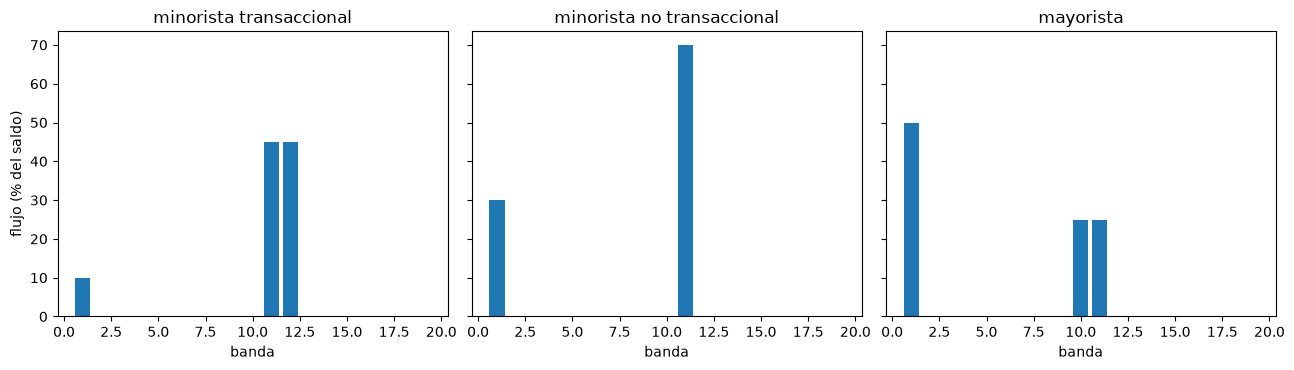

In [3]:
# Dividir cada segmento del balance de 2022-Q2 con los topes del estándar y dibujar los flujos por banda
splits = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, seg in zip(axes, out["nmd_segments"]):
    args = (seg["balance"], seg["category"], seg["requested_core_share"], seg["requested_core_maturity_years"])
    r = slotting.nmd_split(*args)
    splits[seg["category"]] = r
    asked = f"{r.requested_core_share:.2f}/{r.requested_core_maturity_years:.1f}"
    cap = f"{r.core_share_cap:.2f}/{r.core_maturity_cap_years:.1f}"
    used = f"{r.core_share_used:.2f}/{r.core_maturity_used_years:.1f}"
    wam = (r.flows[1:] * MID[1:]).sum() / r.flows[1:].sum()
    print(f"{NAME[seg['category']]}: saldo {seg['balance']:,.0f}")
    print(f"    pedido {asked} | tope {cap} | usado {used} | tope aplicado: {NAME[r.cap_applied]}")
    print(f"    plazo promedio de la parte estable (a): {wam:.4f}")
    ax.bar(np.arange(1, 20), r.flows / seg["balance"] * 100)
    ax.set_title(NAME[seg["category"]])
    ax.set_xlabel("banda")
axes[0].set_ylabel("flujo (% del saldo)")
fig.tight_layout()
plt.show()

Los tres paneles muestran la misma regla sobre tres saldos. La parte no estable, 10, 30 o 50 por ciento del saldo según el tope, está en la primera barra, a la vista; la parte estable está en las barras de las dos bandas que encierran su plazo, 5 años para el segmento minorista transaccional, 4,5 para el no transaccional y 4 para el mayorista, y el plazo promedio impreso de la parte estable es exactamente el plazo usado. Los pedidos del producto (95, 75 y 60 por ciento) estaban sobre todos los topes, así que todos los topes actuaron. La imagen muestra proporciones del saldo, no dinero: el segmento mayorista es de 185 mil millones de dólares frente a menos de 3 mil millones de los dos minoristas, así que la barra mayorista decide el resultado.

Lo que valen los topes. La celda siguiente toma el segmento mayorista, el más grande por lejos, y calcula el valor presente de sus flujos con los topes y con el pedido tal como se declaró (`enforce_caps=False`), usando la curva cero de la fecha. El pedido es más largo y más estable de lo que el estándar permite, así que los depósitos parecen más duraderos, su valor presente como pasivo es menor y el EVE del banco es mayor: los topes impiden que el supuesto haga ver al banco más seguro de lo que el estándar permite.

tope aplicado: con topes sí | sin topes no
valor presente del pasivo con los topes      174,964,140
valor presente del pasivo como se pidió      169,928,511
EVE aumentado por no aplicar los topes        5,035,629


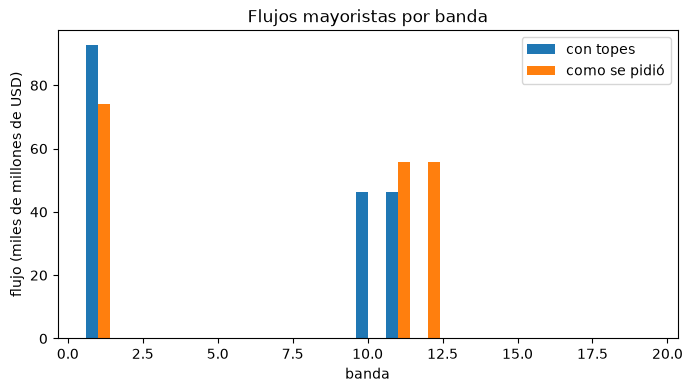

In [4]:
# Los depósitos mayoristas con los topes y con el pedido tal como se declaró: valor presente y flujos por banda
seg = next(s for s in out["nmd_segments"] if s["category"] == "wholesale")
args = (seg["balance"], "wholesale", seg["requested_core_share"], seg["requested_core_maturity_years"])
capped = slotting.nmd_split(*args)
asked = slotting.nmd_split(*args, enforce_caps=False)
pv_capped = eve_nii.eve(capped.flows, r0, MID)
pv_asked = eve_nii.eve(asked.flows, r0, MID)
print("tope aplicado: con topes", NAME[capped.cap_applied], "| sin topes", NAME[asked.cap_applied])
print(f"valor presente del pasivo con los topes {pv_capped:16,.0f}")
print(f"valor presente del pasivo como se pidió {pv_asked:16,.0f}")
print(f"EVE aumentado por no aplicar los topes {pv_capped - pv_asked:16,.0f}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(np.arange(1, 20) - 0.2, capped.flows / 1e6, 0.4, label="con topes")
ax.bar(np.arange(1, 20) + 0.2, asked.flows / 1e6, 0.4, label="como se pidió")
ax.set_xlabel("banda")
ax.set_ylabel("flujo (miles de millones de USD)")
ax.set_title("Flujos mayoristas por banda")
ax.legend()
plt.show()

El pedido tal como se declaró pone 60 por ciento del saldo mayorista en la parte estable y lo reparte en torno a 5 años, así que sus barras son más bajas a la vista y más altas en las bandas largas que las con tope. Un pasivo que está más lejos vale menos hoy, y por eso el valor presente baja de la cifra con tope a la del pedido y el EVE sube por la diferencia impresa arriba. Los topes impiden entonces que un supuesto haga ver al banco más seguro de lo que el estándar permite. Lo que la figura no muestra es cuán grande es esto frente al banco: esa comparación con el Tier 1 llega en los Resultados.

### Paso 2: la cartera replicante

El estándar pone topes a los supuestos del depósito; el modelo propio de un banco tiene que elegirlos. El modelo interno más común es la **cartera replicante estática**: elegir pesos $w_j \ge 0$ que sumen uno sobre tramos rodantes de plazos $m_j$ de modo que el margen $\mu_t = \sum_j w_j\, y_{jt} - i_t$, el rendimiento replicante menos la tasa al cliente $i_t$, tenga la menor varianza posible. Un tramo rodante de plazo $m$ reinvertido en partes iguales durante su vida tiene un plazo promedio ponderado de $m/2$, así que el plazo implícito del depósito es

$$WAM = \frac{1}{2} \sum_j w_j\, m_j$$

(BCBS d368, nota 38, https://www.bis.org/bcbs/publ/d368.htm, según se lee en el dossier 05, D.3; la versión dinámica es Kalkbrener y Willing, 2004, https://doi.org/10.1016/S0378-4266(03)00131-6). La función `replicating_portfolio` del motor resuelve el problema con restricciones de forma exacta hasta 10 tramos, y `weighted_average_maturity` aplica la fórmula. Primero, los ajustes del proceso del producto: los pesos del modelo mayorista en cada fecha y el plazo promedio que el motor da para ellos.

2021-12-31 mayorista | {0.25: 0.0493, 10.0: 0.9507}
    plazo promedio (a) 4.7595 | volatilidad del margen 0.00803
2022-06-30 mayorista | {0.25: 0.1631, 10.0: 0.8369}
    plazo promedio (a) 4.2049 | volatilidad del margen 0.00768
2022-12-31 mayorista | {10.0: 1.0}
    plazo promedio (a) 5.0000 | volatilidad del margen 0.00823


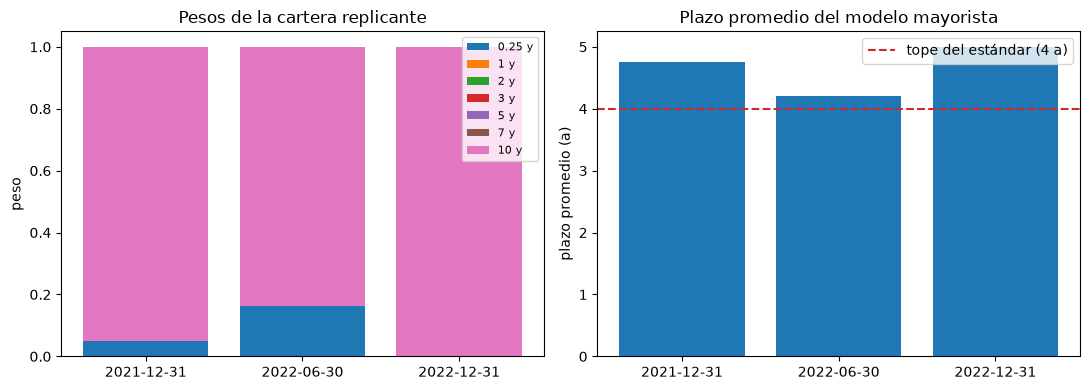

In [5]:
# Los pesos de la cartera replicante ajustados en cada fecha, y el plazo promedio que el motor da para ellos
models = fit["nmd_models"]
years = np.array([t["maturity_years"] for t in models[0]["tranches"]])
weights = np.array([[t["weight"] for t in m["tranches"]] for m in models])
wams = [behavioural.weighted_average_maturity(years, w) for w in weights]
for m, w, wam in zip(models, weights, wams):
    used = {float(y): round(float(x), 4) for y, x in zip(years, w) if x > 0}
    print(m["valuation_date"], NAME[m["category"]], "|", used)
    print(f"    plazo promedio (a) {wam:.4f} | volatilidad del margen {m['margin_volatility']:.5f}")
dates = [m["valuation_date"] for m in models]
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
bottom = np.zeros(len(models))
for j, y in enumerate(years):
    left.bar(dates, weights[:, j], bottom=bottom, label=f"{y:g} y")
    bottom += weights[:, j]
left.set_ylabel("peso")
left.set_title("Pesos de la cartera replicante")
left.legend(fontsize=8)
right.bar(dates, wams)
right.axhline(4.0, color="tab:red", linestyle="--", label="tope del estándar (4 a)")
right.set_ylabel("plazo promedio (a)")
right.set_title("Plazo promedio del modelo mayorista")
right.legend()
fig.tight_layout()
plt.show()

El panel izquierdo muestra los pesos saltando: en 2021-Q4 casi todo está en el tramo de 10 años, en 2022-Q2 una sexta parte está en el tramo de 3 meses, y en 2022-Q4 todo está de nuevo en el tramo de 10 años. El panel derecho convierte los pesos en el plazo promedio del depósito, 4,76, 4,20 y 5,00 años, y el último queda sobre la línea roja de 4 años que el estándar permite a los depósitos mayoristas. Un promedio ponderado de tramos de hasta 10 años no puede superar 5 años, así que el último ajuste llegó al techo de su propio diseño. La imagen muestra tres ajustes de un modelo y no puede decir si los saltos son del mercado o del estimador; la celda siguiente lo prueba con datos de verdad conocida.

Los pesos saltan entre fechas: en 2021-Q4 casi todo está en el tramo de 10 años, en 2022-Q4 está entero allí. El historial viene de los reportes del banco, que no se pueden volver a correr aquí; para ver cómo se comporta el optimizador, la celda siguiente construye un **ejemplo didáctico construido con verdad conocida**, con semilla: cinco tramos, curvas de rendimiento a partir de dos factores persistentes más ruido, y una tasa al cliente que es exactamente 40 por ciento del tramo de 1 año y 60 por ciento del tramo de 5 años, menos un margen, más ruido. No son datos del banco. El motor devuelve pesos cercanos a la verdad pero no iguales, porque los rendimientos de los tramos se mueven juntos, y un cambio pequeño en la muestra mueve los pesos entre tramos casi equivalentes: la inestabilidad que prueba el notebook 05.

pesos del motor: [0.    0.371 0.042 0.56  0.027] | suma 1.0
plazo promedio: motor 1.7632 | verdadero 1.7000
volatilidad del margen 0.00019


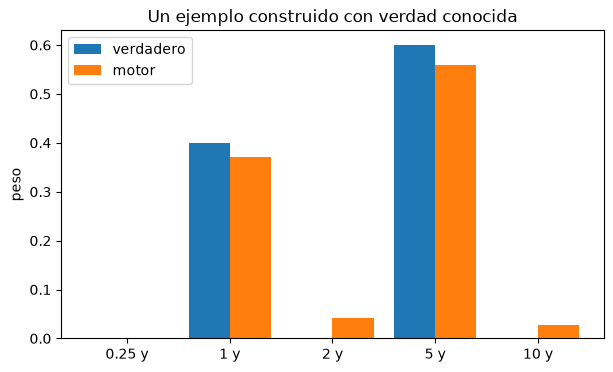

In [6]:
# Un ejemplo construido con verdad conocida (con semilla): el motor recupera los pesos de forma aproximada
rng = np.random.default_rng(42)
n_q = 60
level, slope = np.zeros(n_q), np.zeros(n_q)
level[0], slope[0] = 0.03, 0.01
for t in range(1, n_q):
    level[t] = 0.03 + 0.9 * (level[t - 1] - 0.03) + rng.normal(0, 0.002)
    slope[t] = 0.01 + 0.8 * (slope[t - 1] - 0.01) + rng.normal(0, 0.002)
grid_years = np.array([0.25, 1.0, 2.0, 5.0, 10.0])
shape = 1 - np.exp(-grid_years[None, :] / 2)
tranche_yields = level[:, None] + slope[:, None] * shape + rng.normal(0, 0.0003, (n_q, 5))
client_rate = 0.4 * tranche_yields[:, 1] + 0.6 * tranche_yields[:, 3] - 0.01 + rng.normal(0, 0.0002, n_q)
portfolio = behavioural.replicating_portfolio(client_rate, tranche_yields, grid_years)
true_weights = np.array([0.0, 0.4, 0.0, 0.6, 0.0])
print("pesos del motor:", np.round(portfolio.weights, 3), "| suma", round(float(portfolio.weights.sum()), 6))
wam_engine = behavioural.weighted_average_maturity(grid_years, portfolio.weights)
wam_true = behavioural.weighted_average_maturity(grid_years, true_weights)
print(f"plazo promedio: motor {wam_engine:.4f} | verdadero {wam_true:.4f}")
print(f"volatilidad del margen {portfolio.margin_volatility:.5f}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(np.arange(5) - 0.2, true_weights, 0.4, label="verdadero")
ax.bar(np.arange(5) + 0.2, portfolio.weights, 0.4, label="motor")
ax.set_xticks(np.arange(5), [f"{y:g} y" for y in grid_years])
ax.set_ylabel("peso")
ax.set_title("Un ejemplo construido con verdad conocida")
ax.legend()
plt.show()

El motor encuentra los dos tramos verdaderos, el de 1 año y el de 5 años, con pesos cercanos a 0,4 y 0,6, pero deja pesos pequeños en sus vecinos, los tramos de 2 y de 10 años. Es la inestabilidad en pequeño: los rendimientos de los tramos se mueven juntos, así que una cartera con un poco de un vecino replica casi igual de bien la tasa al cliente que la verdadera, y el optimizador no tiene una razón fuerte para preferir una u otra. El plazo promedio se mueve menos que los pesos, 1,76 años frente a un verdadero 1,70, y por eso los profesionales citan el plazo y no los pesos. El ejemplo es construido y con semilla, no son datos del banco, y muestra un solo sorteo, no la dispersión de las estimaciones.

### Paso 3: el beta de depósitos

La tasa que un banco paga por un depósito no sigue a la tasa de mercado uno a uno. El **beta de depósitos** es el traspaso, y es asimétrico: un banco traspasa las alzas despacio y las bajas rápido. Con la tasa al cliente $i$, un cambio de mercado $\Delta r$ y los betas al alza y a la baja:

$$i_{nueva} = i + \beta\, \Delta r, \qquad \beta = \beta_{alza}\ \text{si}\ \Delta r \ge 0,\ \beta_{baja}\ \text{en otro caso}$$

(Drechsler, Savov y Schnabl, 2021, https://doi.org/10.1111/jofi.13013; dossier 05, D.3). Un beta bajo significa que los depósitos se comportan como pasivos de tasa fija y larga duración, y por eso importa. La función `deposit_beta_passthrough` del motor no aplica piso al resultado; el llamador lo aplica. El modelo versionado ajusta ambos betas en cada fecha por mínimos cuadrados a través del origen sobre los últimos 16 trimestres del costo de los depósitos contra el rendimiento del Tesoro a 3 meses. La celda siguiente imprime los betas ajustados en las tres fechas y los aplica a una tasa al cliente de 1 por ciento para un movimiento de mercado de +100 y de -100 pb.

2021-12-31 beta al alza 0.0236 beta a la baja 0.0315
    tasa al cliente tras +100 pb 0.01024 | tras -100 pb 0.00969
2022-06-30 beta al alza 0.0748 beta a la baja 0.0315
    tasa al cliente tras +100 pb 0.01075 | tras -100 pb 0.00969
2022-12-31 beta al alza 0.2611 beta a la baja 0.0315
    tasa al cliente tras +100 pb 0.01261 | tras -100 pb 0.00969
beta usado por el NII dinámico al 2022-Q2 (el valor al alza): 0.0748


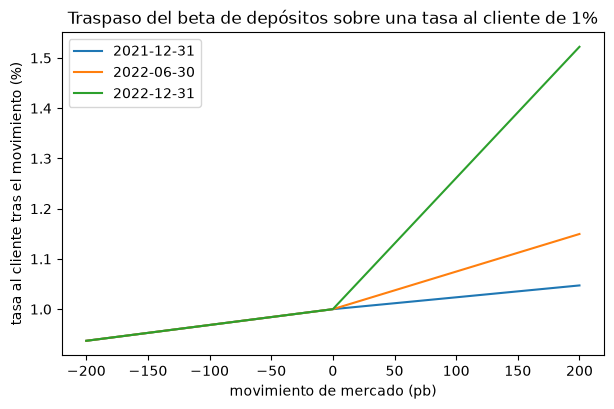

In [7]:
# Los betas ajustados en las tres fechas y el traspaso de movimientos de mercado sobre una tasa al cliente de 1%
moves = np.linspace(-0.02, 0.02, 41)
fig, ax = plt.subplots(figsize=(7, 4.2))
for m in fit["nmd_models"]:
    b = m["deposit_beta"]
    client = [behavioural.deposit_beta_passthrough(0.01, dr, b["up"], b["down"]) for dr in moves]
    ax.plot(moves * 1e4, np.array(client) * 100, label=m["valuation_date"])
    up = behavioural.deposit_beta_passthrough(0.01, 0.01, b["up"], b["down"])
    down = behavioural.deposit_beta_passthrough(0.01, -0.01, b["up"], b["down"])
    print(f"{m['valuation_date']} beta al alza {b['up']:.4f} beta a la baja {b['down']:.4f}")
    print(f"    tasa al cliente tras +100 pb {up:.5f} | tras -100 pb {down:.5f}")
beta_nii = out["assumptions"]["deposit_beta"]["value"]
print("beta usado por el NII dinámico al 2022-Q2 (el valor al alza):", round(beta_nii, 4))
ax.set_xlabel("movimiento de mercado (pb)")
ax.set_ylabel("tasa al cliente tras el movimiento (%)")
ax.set_title("Traspaso del beta de depósitos sobre una tasa al cliente de 1%")
ax.legend()
plt.show()

Cada línea es una tasa al cliente de 1 por ciento tras un movimiento de mercado, y su pendiente es el beta: la mitad derecha, un alza, es algo más plana que la izquierda, una baja, en 2021-Q4, y la pendiente de la mitad derecha se hace más empinada hasta que en 2022-Q4 es ocho veces la de la mitad izquierda, porque el beta al alza ajustado pasa de 0,0236 a 0,2611 mientras el beta a la baja queda en 0,0315. Un banco con el beta más temprano traspasa unos 2,4 pb de un movimiento de +100 pb a sus depositantes, así que sus depósitos parecen pasivos de tasa fija y su EVE ante un alza se ve mejor de lo que es si el beta verdadero resulta mayor. La imagen muestra los betas ajustados y no dice si los depositantes de 2023 los habrían aceptado, que es la pregunta que retoma el tema de liquidez.

### Paso 4: prepago y rescate anticipado

Las hipotecas y los depósitos a plazo se pueden pagar antes, lo que acorta sus flujos. Dos convenciones miden la velocidad. La **mortalidad mensual simple** (SMM) es la fracción del saldo prepagada en un mes, y la **tasa de prepago condicional** (CPR) es la misma velocidad en tasa anual:

$$SMM = 1 - (1 - CPR)^{1/12}, \qquad CPR = 1 - (1 - SMM)^{12}$$

(Fuster, Lucca y Vickery, 2022, FRBNY Staff Report 1001, https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr1001.pdf; dossier 05, D.4). El **referente PSA** es una rampa estándar: con 100 por ciento PSA el CPR es 0,2 por ciento en el mes 1 y sube 0,2 por ciento al mes hasta 6 por ciento en el mes 30, plano después; $x$ por ciento PSA la escala, $CPR_m = \frac{x}{100}\min(0{,}002\, m,\ 0{,}06)$ (el texto primario de SIFMA no se obtuvo; el motor marca la fórmula como NO VERIFICADA contra él). El marco estandarizado escala las tasas base por choque con los multiplicadores de SRP31.119 (Tabla 5) y SRP31.125 (Tabla 6):

$$CPR_i = \min(1,\ \gamma_i\, CPR^0), \qquad TDRR_i = \min(1,\ u_i\, TDRR^0)$$

La celda siguiente convierte el supuesto de CPR de 8 por ciento del banco, imprime la rampa PSA en algunos meses para 100 y 150 por ciento, e imprime los multiplicadores y las tasas por choque.

CPR 0.0800 -> SMM 0.006924 -> CPR 0.0800
PSA 100 y 150 en los meses 1, 10, 30 y 60: [0.002 0.02  0.06  0.06 ] [0.003 0.03  0.09  0.09 ]
paralelo al alza       CPR  0.0640  TDRR  0.0600
paralelo a la baja     CPR  0.0960  TDRR  0.0400
empinamiento           CPR  0.0640  TDRR  0.0400
aplanamiento           CPR  0.0960  TDRR  0.0600
corto al alza          CPR  0.0640  TDRR  0.0600
corto a la baja        CPR  0.0960  TDRR  0.0400


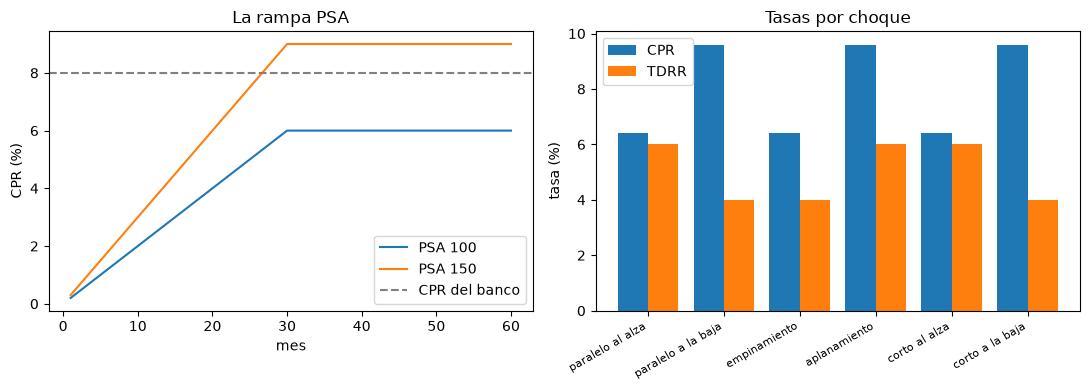

In [8]:
# Convertir CPR y SMM, leer la rampa PSA y escalar las tasas base por choque con los multiplicadores del estándar
cpr0 = out["assumptions"]["prepayment_cpr"]["value"]
tdrr0 = out["assumptions"]["term_deposit_redemption_rate"]["value"]
smm = slotting.smm_from_cpr(cpr0)
print(f"CPR {cpr0:.4f} -> SMM {smm:.6f} -> CPR {slotting.cpr_from_smm(smm):.4f}")
months = np.arange(1, 61)
psa100, psa150 = slotting.psa_cpr(months, 100.0), slotting.psa_cpr(months, 150.0)
print("PSA 100 y 150 en los meses 1, 10, 30 y 60:", psa100[[0, 9, 29, 59]], psa150[[0, 9, 29, 59]])
cpr_s = [slotting.prepayment_cpr(s, cpr0) for s in shocks.SHOCKS]
tdrr_s = [slotting.term_deposit_redemption_rate(s, tdrr0) for s in shocks.SHOCKS]
for s, c, t in zip(shocks.SHOCKS, cpr_s, tdrr_s):
    print(f"{NAME[s]:22s} CPR {c:7.4f}  TDRR {t:7.4f}")
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.plot(months, psa100 * 100, label="PSA 100")
left.plot(months, psa150 * 100, label="PSA 150")
left.axhline(cpr0 * 100, color="grey", linestyle="--", label="CPR del banco")
left.set_xlabel("mes")
left.set_ylabel("CPR (%)")
left.set_title("La rampa PSA")
left.legend()
x = np.arange(6)
right.bar(x - 0.2, np.array(cpr_s) * 100, 0.4, label="CPR")
right.bar(x + 0.2, np.array(tdrr_s) * 100, 0.4, label="TDRR")
right.set_xticks(x, [NAME[s] for s in shocks.SHOCKS], rotation=30, ha="right", fontsize=8)
right.set_ylabel("tasa (%)")
right.set_title("Tasas por choque")
right.legend()
fig.tight_layout()
plt.show()

A la izquierda la rampa PSA sube mes a mes hasta su techo en el mes 30, 6 por ciento con 100 PSA y 9 por ciento con 150, y la línea punteada plana del 8 por ciento del banco queda entre los dos techos, así que el banco supone un prepago más rápido que la rampa estándar pero más lento que 150 por ciento de ella. A la derecha los multiplicadores del estándar doblan las tasas base por choque: los choques paralelo al alza, empinamiento y corto al alza bajan la tasa de prepago a 6,4 por ciento, y los otros tres la suben a 9,6 por ciento, mientras que el rescate anticipado de depósitos a plazo es de 6 por ciento bajo los choques paralelo al alza, corto al alza y aplanamiento y de 4 por ciento bajo el resto. La imagen muestra supuestos, no comportamiento: el reporte de condición no trae historial de préstamos contra el cual probarlos.

Cuando el banco tiene historial por préstamo, el modelo de los profesionales es un **logit del SMM** sobre el incentivo de refinanciar (la tasa del contrato menos la tasa de mercado) y la antigüedad (la edad del préstamo en meses): $SMM = 1 / (1 + e^{-(b_0 + b_1\, incentivo + b_2\, antiguedad)})$ (dossier 05, D.4). La función `fit_prepayment_logit` del motor lo ajusta por máxima verosimilitud con el método de Newton y dice con claridad cuando no converge (sin excepción: la generación del documento usa entonces el referente PSA). El reporte no trae historial por préstamo, así que el banco de este caso no ajusta uno; la celda siguiente ajusta un **ejemplo construido con verdad conocida**, con semilla, para mostrar la función, los errores estándar y la recuperación de los coeficientes.

préstamos: 5000 | proporción prepagada: 0.0358
convergió: sí
b0: verdadero   -5.000 | estimación   -4.856 | error estándar   0.226
    dentro de 2 errores estándar sí
b1: verdadero   60.000 | estimación   56.801 | error estándar   7.385
    dentro de 2 errores estándar sí
b2: verdadero    0.030 | estimación    0.024 | error estándar   0.005
    dentro de 2 errores estándar sí


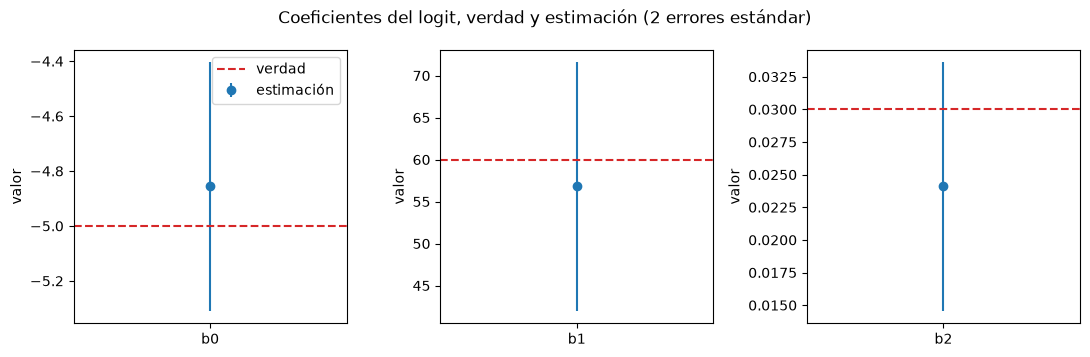

In [9]:
# Ajustar el logit de prepago sobre un ejemplo construido con semilla y coeficientes conocidos, y leer la recuperación
rng = np.random.default_rng(42)
n_loans = 5000
incentive = rng.uniform(-0.01, 0.03, n_loans)
seasoning = rng.uniform(1, 60, n_loans)
true_coef = np.array([-5.0, 60.0, 0.03])
score = true_coef[0] + true_coef[1] * incentive + true_coef[2] * seasoning
prepaid = (rng.uniform(size=n_loans) < 1.0 / (1.0 + np.exp(-score))).astype(int)
logit = behavioural.fit_prepayment_logit(incentive, seasoning, prepaid)
print("préstamos:", logit.n, "| proporción prepagada:", round(float(prepaid.mean()), 4))
print("convergió:", NAME[logit.converged])
for name, truth, est, err in zip(("b0", "b1", "b2"), true_coef, logit.coef, logit.std_err):
    inside = NAME[bool(abs(est - truth) < 2 * err)]
    print(f"{name}: verdadero {truth:8.3f} | estimación {est:8.3f} | error estándar {err:7.3f}")
    print(f"    dentro de 2 errores estándar {inside}")
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, name, truth, est, err in zip(axes, ("b0", "b1", "b2"), true_coef, logit.coef, logit.std_err):
    ax.errorbar([0], [est], yerr=[2 * err], fmt="o", label="estimación")
    ax.axhline(truth, color="tab:red", linestyle="--", label="verdad")
    ax.set_xticks([0], [name])
    ax.set_ylabel("valor")
axes[0].legend()
fig.suptitle("Coeficientes del logit, verdad y estimación (2 errores estándar)")
fig.tight_layout()
plt.show()

Cada panel muestra un coeficiente: el punto es la estimación, la barra son dos errores estándar a cada lado, y la línea roja es la verdad con que se generaron los datos. Las tres líneas rojas caen dentro de sus barras, así que el logit recupera los coeficientes dentro del error de muestreo, con 5.000 préstamos y una proporción prepagada cercana a 3,6 por ciento. La pendiente sobre la antigüedad, b2, tiene la barra más ancha respecto de su tamaño, y el intercepto la más angosta. Es un ejemplo construido: muestra que la función anda y cómo se ven sus errores estándar, y no dice nada del banco, cuyo reporte de condición no trae historial por préstamo, así que el documento del banco usa el referente PSA.

### Paso 5: el EVE con y sin la capa de comportamiento

Los seis choques del notebook 02 mueven el EVE. La **medida de riesgo EVE** es el peor de los seis: para cada choque, la suma de las monedas con pérdida, y luego el máximo entre choques (SRP31.129); con una sola moneda es el mayor delta EVE positivo, o cero si ninguno es positivo. La **prueba de valores atípicos supervisora** la compara con 15 por ciento del capital Tier 1 (SRP31.82 a SRP31.83; dossier 01, H.5) y se supera solo si la razón es estrictamente mayor. El proceso del producto calculó el delta EVE de cada choque dos veces, con los flujos conductuales con tope del Paso 1 y con todo depósito a la vista a un día (contractual), y versionó ambos. La celda siguiente toma los seis valores versionados de cada tratamiento bajo la calibración 2024, calcula la medida con `eve_risk_measure` (una matriz de seis choques por una moneda) y la prueba con `outlier_test`, y dibuja los seis delta EVE de cada tratamiento.

paralelo al alza              3,389,351       12,611,380
paralelo a la baja           -4,783,706      -15,915,274
empinamiento                  3,418,185        8,589,837
aplanamiento                 -2,993,642       -5,921,844
corto al alza                    43,834        3,316,400
corto a la baja                  89,516       -3,343,657
conductual: medida 3,418,185 | Tier 1 16,349,000
    razón 0.2091 | umbral 0.15 | superado sí
contractual: medida 12,611,380 | Tier 1 16,349,000
    razón 0.7714 | umbral 0.15 | superado sí


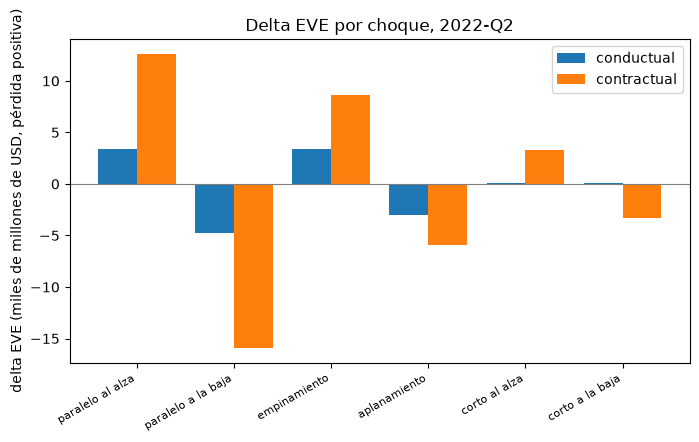

In [10]:
# Los seis delta EVE de cada tratamiento al 2022-Q2, la medida de riesgo EVE y la prueba de valores atípicos
rows = {s["shock"]: s for s in out["behavioural_comparison"] if s["calibration"] == "2024"}
tier1 = out["scenarios"][0]["outlier"]["tier1"]
measure, test = {}, {}
for s in shocks.SHOCKS:
    print(f"{NAME[s]:22s} {rows[s]['delta_eve_behavioural']:16,.0f} {rows[s]['delta_eve_contractual']:16,.0f}")
for treatment in ("behavioural", "contractual"):
    deltas = np.array([rows[s][f"delta_eve_{treatment}"] for s in shocks.SHOCKS]).reshape(6, 1)
    measure[treatment] = eve_nii.eve_risk_measure(deltas)
    test[treatment] = eve_nii.outlier_test(measure[treatment], tier1)
    t = test[treatment]
    print(f"{NAME[treatment]}: medida {measure[treatment]:,.0f} | Tier 1 {tier1:,.0f}")
    print(f"    razón {t.ratio:.4f} | umbral {t.threshold:.2f} | superado {NAME[t.breached]}")
x = np.arange(6)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - 0.2, [rows[s]["delta_eve_behavioural"] / 1e6 for s in shocks.SHOCKS], 0.4, label=NAME["behavioural"])
ax.bar(x + 0.2, [rows[s]["delta_eve_contractual"] / 1e6 for s in shocks.SHOCKS], 0.4, label=NAME["contractual"])
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(x, [NAME[s] for s in shocks.SHOCKS], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("delta EVE (miles de millones de USD, pérdida positiva)")
ax.set_title("Delta EVE por choque, 2022-Q2")
ax.legend()
plt.show()

Las barras contractuales son más altas que las conductuales bajo todo choque que pierde, por un factor de unas cuatro veces para el choque paralelo al alza, y el peor choque cambia con el tratamiento: el empinamiento con la lectura conductual, el paralelo al alza con la contractual. La medida de riesgo EVE es la barra positiva más alta de cada tratamiento, y por eso su razón con el Tier 1 es la cifra impresa arriba. La imagen muestra los delta EVE que el producto versionó y el motor solo los agrega, así que dice qué hace la capa de comportamiento con la medida y no si la capa es correcta.

El motor une las dos medidas en una sola prueba, `irrbb.eve_with_without_behavioural`, porque la revisión de SVB enseñó que el supuesto de comportamiento es la palanca que más mueve la medida (dossier 05, D.7). El estadístico de la prueba es la diferencia entre la medida contractual y la conductual como proporción del Tier 1, y su luz es verde si el estadístico absoluto es como máximo 0,05, ámbar como máximo 0,15 y roja por encima (umbrales internos de Contraste, no regulatorios); y es roja sea cual sea el tamaño cuando la medida conductual pasa la prueba de valores atípicos y la contractual la supera, lo que significa que los supuestos **esconden un exceso**. La celda siguiente la corre en las tres fechas de valoración, midiendo cada tratamiento con el motor, y dibuja las razones de valores atípicos contra la línea de 15 por ciento.

2021-Q4: estadístico (diferencia sobre Tier 1) 0.7222
    diferencia en dinero 10,560,453 | exceso escondido: no
    razón 0.3406 / 1.0629
2022-Q2: estadístico (diferencia sobre Tier 1) 0.5623
    diferencia en dinero 9,193,196 | exceso escondido: no
    razón 0.2091 / 0.7714
2022-Q4: estadístico (diferencia sobre Tier 1) 0.4655
    diferencia en dinero 7,911,085 | exceso escondido: no
    razón 0.1808 / 0.6463


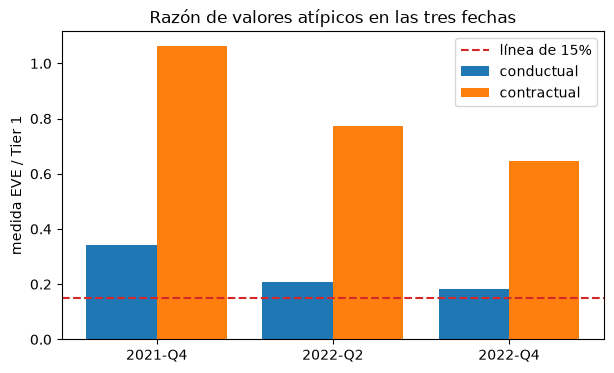

In [11]:
# La medida, la razón de valores atípicos y la prueba con y sin conducta en las tres fechas de valoración
ratios = {"behavioural": [], "contractual": []}
for q, d in docs.items():
    rows_q = {s["shock"]: s for s in d["outputs"]["behavioural_comparison"] if s["calibration"] == "2024"}
    tier1_q = d["outputs"]["scenarios"][0]["outlier"]["tier1"]
    measures = {}
    for treatment in ratios:
        deltas = np.array([rows_q[s][f"delta_eve_{treatment}"] for s in shocks.SHOCKS]).reshape(6, 1)
        measures[treatment] = eve_nii.eve_risk_measure(deltas)
        ratios[treatment].append(eve_nii.outlier_test(measures[treatment], tier1_q).ratio)
    result = rv_irrbb.eve_with_without_behavioural(measures["behavioural"], measures["contractual"], tier1_q)
    hidden_flag = NAME[result.extras["hidden_breach"]]
    print(f"{q}: estadístico (diferencia sobre Tier 1) {result.statistic:.4f}")
    print(f"    diferencia en dinero {result.metric:,.0f} | exceso escondido: {hidden_flag}")
    print(f"    razón {ratios['behavioural'][-1]:.4f} / {ratios['contractual'][-1]:.4f}")
x = np.arange(3)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - 0.2, ratios["behavioural"], 0.4, label=NAME["behavioural"])
ax.bar(x + 0.2, ratios["contractual"], 0.4, label=NAME["contractual"])
ax.axhline(0.15, color="tab:red", linestyle="--", label="línea de 15%")
ax.set_xticks(x, list(docs))
ax.set_ylabel("medida EVE / Tier 1")
ax.set_title("Razón de valores atípicos en las tres fechas")
ax.legend()
plt.show()

Ambos tratamientos quedan sobre la línea punteada de 15 por ciento en todas las fechas, así que la capa de comportamiento no mueve aquí la medida a través de la línea de valores atípicos: solo baja la razón, de 0,34 en 2021-Q4 a 0,21 y 0,18, mientras la razón contractual cae de 1,06 a 0,65. El estadístico de la prueba con y sin conducta, la diferencia entre las dos medidas sobre el Tier 1, es grande en todas las fechas, y la prueba es roja por ese tamaño y no por un exceso escondido. La imagen muestra tres fechas de un banco; no puede decir si la tendencia a la baja es desapalancamiento o el efecto de un supuesto cambiante, y la prueba de validación del notebook 05 hace esa pregunta.

¿Cómo se vería un **exceso escondido**? Las tres fechas anteriores superan la prueba de valores atípicos bajo ambos tratamientos, así que la luz roja del motor viene del tamaño de la diferencia, no de un exceso escondido. La celda siguiente llama a la misma función del motor con **números construidos** (no los del banco) para mostrar el otro rojo: una medida conductual en 14 por ciento del Tier 1, bajo la línea de 15 por ciento, frente a una contractual en 40 por ciento. El supuesto de comportamiento hace que el banco pase una prueba que fallaría con la lectura contractual. Es el patrón que describe la revisión de la Reserva Federal en el banco quebrado, mostrado aquí como una llamada a la función, no como un hallazgo sobre ningún banco.

In [12]:
# Números construidos: la medida conductual pasa la línea de 15 por ciento y la contractual la supera
hidden = rv_irrbb.eve_with_without_behavioural(0.14 * 1000.0, 0.40 * 1000.0, 1000.0)
print("luz:", hidden.light.value, "| estadístico:", round(hidden.statistic, 4))
print("exceso escondido:", NAME[hidden.extras["hidden_breach"]])

luz: red | estadístico: 0.26
exceso escondido: sí


## Resultados

**Respuesta:** el supuesto sobre los depósitos mueve la medida EVE por un múltiplo pero no a través de la línea. Al 2022-Q2 la medida de riesgo es 3.418.185 con los flujos conductuales con tope y 12.611.380 con todo depósito a la vista a un día, 3,7 veces más; como proporción del Tier 1 de 16.349.000 son 0,2091 y 0,7714 frente a una línea de 0,15, así que ambas lecturas la superan. La prueba con y sin conducta tiene un estadístico de 0,5623, roja por el tamaño de la diferencia y no por un exceso escondido.

- **Los topes.** Los tres pedidos exceden sus topes, así que los tres se cortan: de 95 a 90 por ciento y de 6 a 5 años para los depósitos minoristas transaccionales, de 75 a 70 por ciento y de 5 a 4,5 años para los minoristas no transaccionales, de 60 a 50 por ciento y de 5 a 4 años para los mayoristas. El pedido tal como se declaró bajaría el valor presente del pasivo mayorista en 5.035.629 y subiría el EVE en otro tanto, cerca de un tercio del Tier 1 del banco: los topes impiden que el supuesto haga ver al banco más seguro de lo que el estándar permite.
- **La cartera replicante.** Los ajustes mayoristas dan un plazo promedio de 4,7595, 4,2049 y 5,0000 años en las tres fechas, y el último llegó al techo de su propio diseño, sobre los 4 años que el estándar permite. En el ejemplo construido el motor encuentra 0,371 y 0,560 en los tramos de 1 y 5 años frente a una verdad de 0,4 y 0,6, así que los pesos son una estimación con objetivo plano, no una medición; un validador debe preguntar cómo se mueven cuando se mueve la ventana (notebook 05).
- **El beta.** El beta al alza ajustado sube de 0,0236 a 0,0748 y a 0,2611 en las tres fechas, mientras el beta a la baja queda en 0,0315, coherente con que los trimestres de alzas entran en las ventanas de estimación. Un banco con un beta de 0,0236 traspasa 2,4 pb de un movimiento de +100 pb a sus depositantes.
- **El prepago.** El CPR de 8 por ciento es un SMM mensual de 0,006924, y el viaje de ida y vuelta devuelve 0,0800. Con 100 por ciento PSA el CPR llega a 0,06 en el mes 30, con 150 por ciento PSA a 0,09, así que el supuesto del banco queda entre los dos techos. Los multiplicadores bajan la tasa de prepago a 0,0640 bajo los choques paralelo al alza, empinamiento y corto al alza y la suben a 0,0960 bajo los otros tres. En el ejemplo construido el logit recupera los tres coeficientes dentro de dos errores estándar.
- **A través de las fechas.** La razón conductual cae de 0,3406 a 0,2091 y a 0,1808 en las tres fechas, hacia la línea; la contractual de 1,0629 a 0,7714 y a 0,6463. La última llamada construida muestra el otro rojo: una medida conductual de 14 por ciento del Tier 1 pasa la prueba, una contractual de 40 por ciento la supera, y el motor lo marca con un estadístico de 0,26.
- **Lo que el notebook no muestra.** La estabilidad de los pesos entre ventanas de estimación y la prueba que marca un cambio de comportamiento en un exceso (notebook 05), el efecto dinámico del beta sobre el margen neto de intereses (notebook 04), y cualquier estimación de prepago sobre préstamos reales: el reporte de condición no trae ninguna.

## Resumen

- Un depósito a la vista es una parte no estable a la vista y una parte estable en las dos bandas que encierran su plazo estable; el estándar pone tope a la proporción estable y al plazo por categoría, y el motor informa el pedido, el tope y el valor usado.
- La cartera replicante elige pesos de tramos que minimizan la varianza del margen; los pesos no son estables porque los rendimientos de los tramos se mueven juntos, y el plazo implícito es la mitad del plazo ponderado de los tramos.
- El beta de depósitos es asimétrico y bajo, lo que hace que los depósitos se comporten como pasivos largos de tasa fija; el prepago y el rescate anticipado se convierten con SMM, CPR, PSA y los multiplicadores por choque.
- La medida de riesgo EVE es el peor de los seis choques; la capa de comportamiento la mueve por un múltiplo, y el motor prueba las dos lecturas juntas y marca un exceso que la lectura conductual esconde.
- Los dos ejemplos construidos tienen verdad conocida y no son datos del banco.

**Qué probar a continuación.** Cambia el pedido de proporción estable de `nmd_split` bajo su tope y mira la marca `cap_applied` y el EVE. Después sigue con el notebook 04, el NII dinámico y las distribuciones.

## Referencias

- BCBS, Standards: Interest rate risk in the banking book, SRP31.82 a SRP31.83 (la prueba de valores atípicos), SRP31.107 a SRP31.112 (depósitos a la vista, Tabla 4), SRP31.119 y SRP31.125 (Tablas 5 y 6) y SRP31.129 (la medida de riesgo EVE). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book, nota 38 (la cartera replicante). https://www.bis.org/bcbs/publ/d368.htm
- Kalkbrener, M. y Willing, J. (2004), Risk management of non-maturing liabilities, Journal of Banking and Finance 28(7). https://doi.org/10.1016/S0378-4266(03)00131-6
- Drechsler, I., Savov, A. y Schnabl, P. (2021), Banking on deposits: maturity transformation without interest rate risk, Journal of Finance 76(3). https://doi.org/10.1111/jofi.13013
- Fuster, A., Lucca, D. y Vickery, J. (2022), Mortgage-backed securities, FRBNY Staff Report 1001. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr1001.pdf
- FDIC, BankFind financials, dominio público. https://api.fdic.gov/banks/financials
- Departamento del Tesoro de EE. UU., Daily Treasury Par Yield Curve Rates, dominio público. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 de la investigación de Contraste, secciones D.3, D.4 y D.7; dossier 01, sección H.5.